# Loan Approval Prediction

# Loan Approval Prediction Using Machine Learning

## 1. Business Understanding

### Problem Statement
Financial institutions receive numerous loan applications from customers.
Manually evaluating every application can be time-consuming.

This project aims to develop a Machine Learning classification model
that predicts whether a loan application will be Approved or Rejected
based on applicant information and financial attributes.

### Project Objective
To build a classification model that predicts loan approval status
using historical loan application data.

### Machine Learning Type
Supervised Learning – Binary Classification

### Target Variable
loan_status

- Approved
- Rejected

### Algorithms
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors
5. Support Vector Machine
6. Gradient Boosting

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC-AUC Score

## Step 2: Import Libraries Required for Data Loading

In [1]:
import pandas as pd
import numpy as np

## Step 3: Load the Dataset

In [2]:
df = pd.read_csv("loan_approval_dataset.csv")
df

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (4269, 13)


## Step 4: Initial Data Inspection

In [4]:
print("Number of Rows:", df.shape[0])

Number of Rows: 4269


In [5]:
print("Number of Columns:", df.shape[1])

Number of Columns: 13


In [6]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='str')


In [7]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [8]:
print("\nStatistical Summary:")
display(df.describe)


Statistical Summary:


<bound method NDFrame.describe of       loan_id   no_of_dependents      education  self_employed   income_annum  \
0           1                  2       Graduate             No        9600000   
1           2                  0   Not Graduate            Yes        4100000   
2           3                  3       Graduate             No        9100000   
3           4                  3       Graduate             No        8200000   
4           5                  5   Not Graduate            Yes        9800000   
...       ...                ...            ...            ...            ...   
4264     4265                  5       Graduate            Yes        1000000   
4265     4266                  0   Not Graduate            Yes        3300000   
4266     4267                  2   Not Graduate             No        6500000   
4267     4268                  1   Not Graduate             No        4100000   
4268     4269                  1       Graduate             No        92000

In [9]:
print("\nFirst 5 Records:")
display(df.head())


First 5 Records:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Step 5: Data Cleaning

In [10]:
# Remove unnecessary spaces from column names

df.columns = df.columns.str.strip()

In [11]:
# Remove duplicate records

print("Duplicates Before Cleaning:", df.duplicated().sum())

Duplicates Before Cleaning: 0


In [12]:
df.drop_duplicates(inplace=True)

In [13]:
print("Duplicates After Cleaning:", df.duplicated().sum())

Duplicates After Cleaning: 0


In [14]:
# Check missing values

print("\nMissing Values:")
display(df.isnull().sum())


Missing Values:


loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [15]:
# Check target column

print("\nTarget Variable Distribution:")
display(df["loan_status"].value_counts())


Target Variable Distribution:


loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [16]:
# Remove loan ID because it is only an identifier

if "loan_id" in df.columns:
    df.drop("loan_id", axis=1, inplace=True)

In [17]:
print("\nDataset Shape After Cleaning:", df.shape)


Dataset Shape After Cleaning: (4269, 12)


## Step 6: Exploratory Data Analysis (EDA)

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

### TARGET VARIABLE DISTRIBUTION

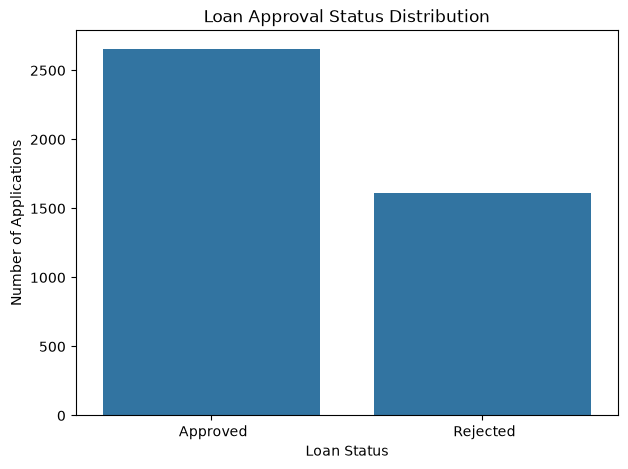

In [19]:
# Visualize Approved and Rejected loan applications

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="loan_status")

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")

plt.show()

### NUMERICAL FEATURE DISTRIBUTION

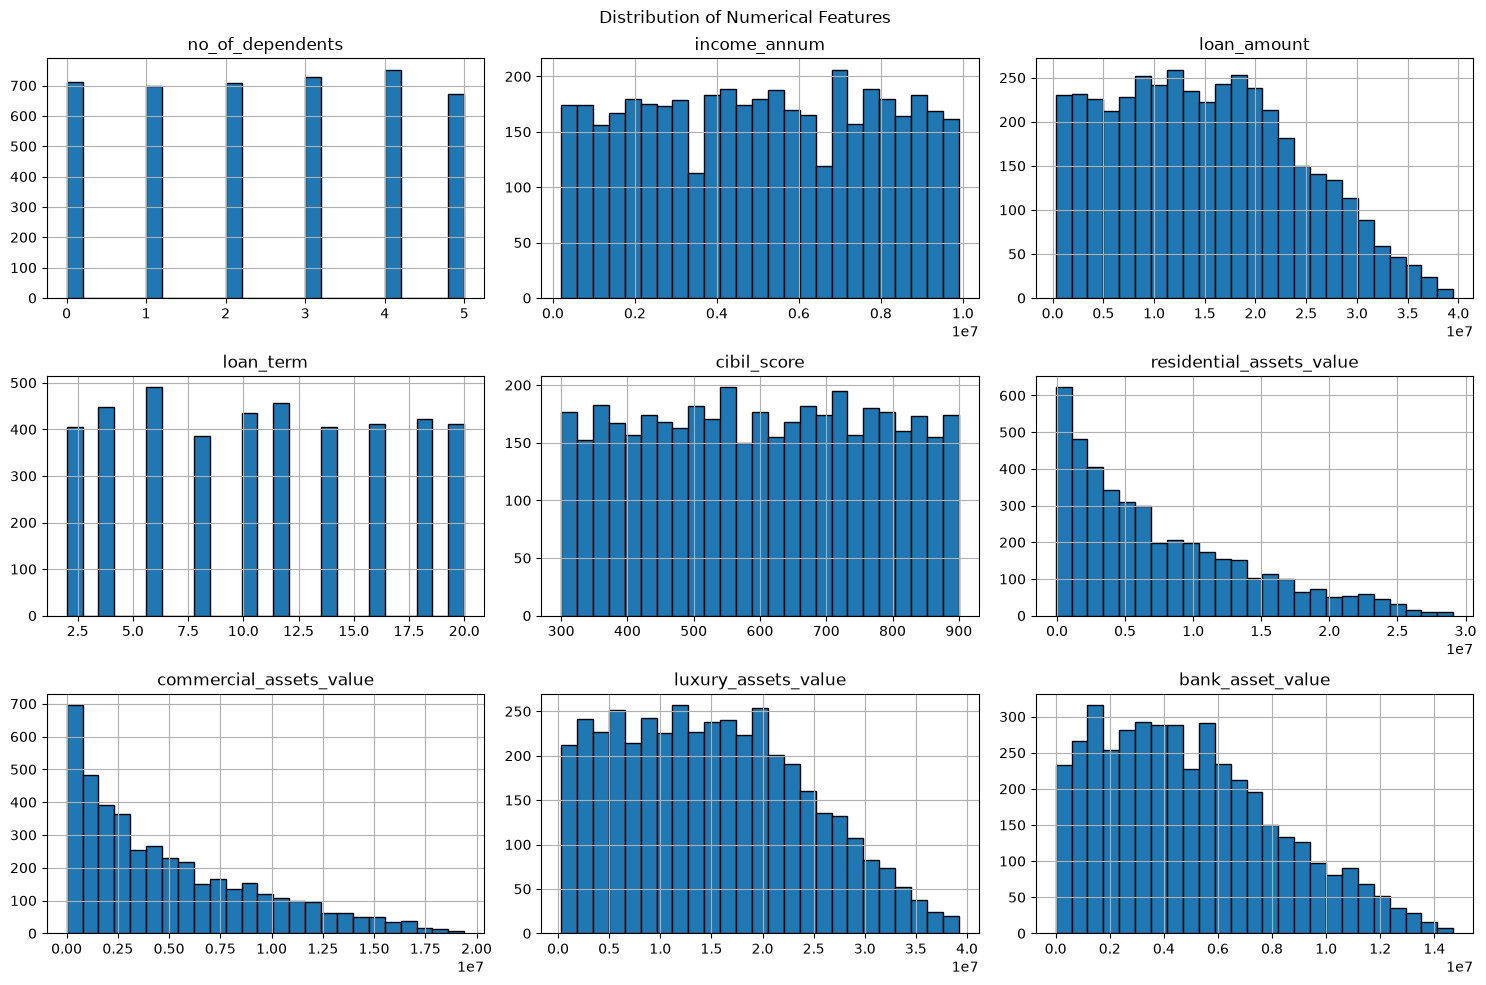

In [20]:
# Analyze numerical feature distributions

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].hist(
    figsize=(15, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")

plt.tight_layout()

plt.show()

### CATEGORICAL FEATURE ANALYSIS

C:\Users\Sravan\AppData\Local\Temp\ipykernel_10808\3774695610.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


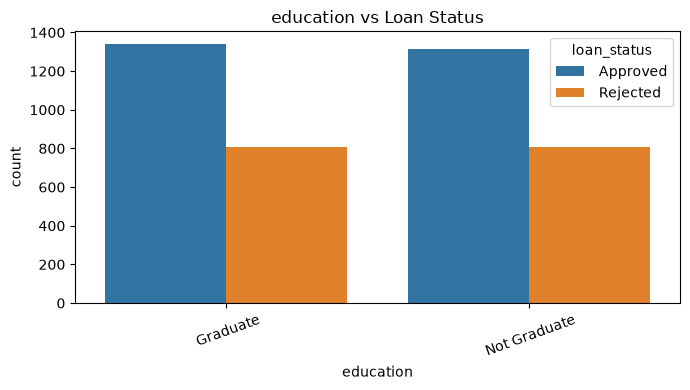

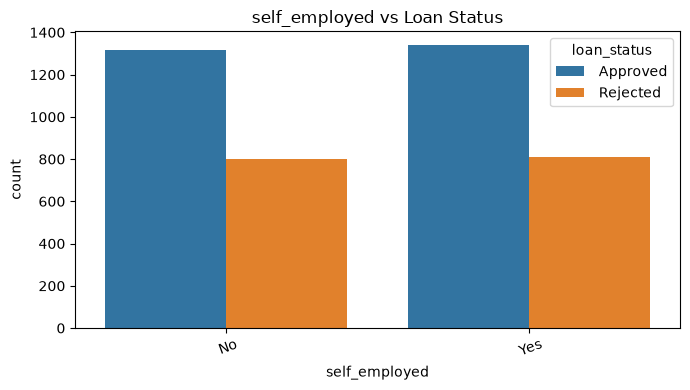

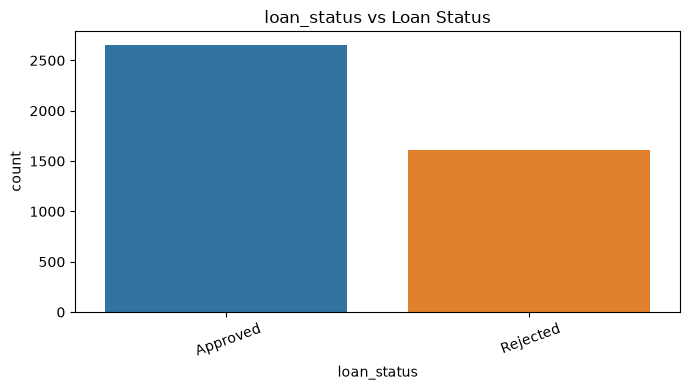

In [21]:
# Analyze categorical features

categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=column,
        hue="loan_status"
    )

    plt.title(f"{column} vs Loan Status")

    plt.xticks(rotation=20)

    plt.tight_layout()

    plt.show()

### CORRELATION HEATMAP

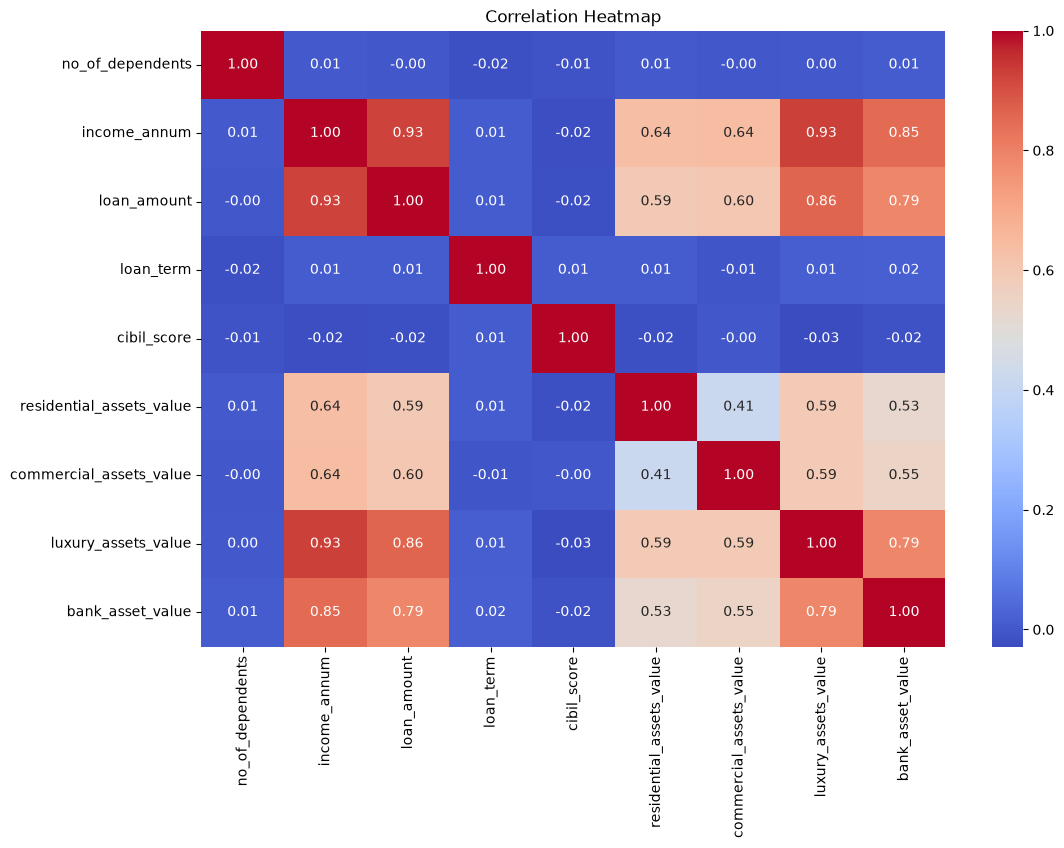

In [22]:
# Analyze correlation between numerical features

plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Step 7: Feature and Target Selection

In [23]:
# Separate independent and dependent variables

X = df.drop("loan_status", axis=1)

y = df["loan_status"].astype(str).str.strip().str.title()

# Convert target labels into numerical values

y = y.map({
    "Approved": 1,
    "Rejected": 0
})

if y.isnull().any():
    raise ValueError("Unexpected loan_status values. Check target labels.")

print("Independent Variables:")
display(X.head())

Independent Variables:


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000


In [24]:
print("\nTarget Variable:")
display(y.head())


Target Variable:


0    1
1    0
2    0
3    0
4    0
Name: loan_status, dtype: int64

In [25]:
print("\nTarget Distribution:")
display(y.value_counts())


Target Distribution:


loan_status
1    2656
0    1613
Name: count, dtype: int64

### Step 8: Train-Test Split

In [26]:
from sklearn.model_selection import train_test_split

In [27]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (3415, 11)
Testing Data Shape: (854, 11)


In [28]:
print("\nTraining Target Distribution:")
display(y_train.value_counts())


Training Target Distribution:


loan_status
1    2125
0    1290
Name: count, dtype: int64

In [29]:
print("\nTesting Target Distribution:")
display(y_test.value_counts())


Testing Target Distribution:


loan_status
1    531
0    323
Name: count, dtype: int64

### Step 9: Feature Preprocessing

We need to handle numerical and categorical columns separately.
- Numerical features: Missing value handling and standardization.
- Categorical features: Missing value handling and one-hot encoding.

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

### IDENTIFY FEATURE TYPES

In [31]:
# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


In [32]:
print("Numerical Features:")
print(numeric_features)

Numerical Features:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [33]:
print("\nCategorical Features:")
print(categorical_features)


Categorical Features:
['education', 'self_employed']


### NUMERICAL PREPROCESSING

In [34]:
# Handle missing values and scale numerical features

numeric_transformer = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())

])

print("Numerical preprocessing created!")

Numerical preprocessing created!


### CATEGORICAL PREPROCESSING

In [35]:
# Handle missing values and encode categorical features

categorical_transformer = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OneHotEncoder(handle_unknown="ignore"))

])

print("Categorical preprocessing created!")

Categorical preprocessing created!


### COMBINE PREPROCESSING

In [36]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(

    transformers=[

        ("num", numeric_transformer, numeric_features),

        ("cat", categorical_transformer, categorical_features)

    ],

    sparse_threshold=0

)

print("Complete preprocessing pipeline created!")

Complete preprocessing pipeline created!


### Step 10: Feature Selection

In [37]:
from sklearn.feature_selection import SelectKBest, f_classif

In [38]:
# Fit preprocessing only on training data to determine feature count

X_train_processed = preprocessor.fit_transform(X_train)

total_features = X_train_processed.shape[1]

print("Total Features After Encoding:", total_features)

Total Features After Encoding: 13


In [39]:
# Select up to 15 features

k_features = min(15, total_features)

print("Number of Features Selected:", k_features)

Number of Features Selected: 13


### Step 11: Model Building

In [40]:
from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC


In [41]:
# Initialize classification models

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )

}

print("Models initialized successfully!")

Models initialized successfully!


### TRAIN ALL MODELS

In [42]:
# Import model evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train and evaluate all models

results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[

        ("preprocessing", preprocessor),

        ("feature_selection", SelectKBest(
            score_func=f_classif,
            k=k_features
        )),

        ("classifier", model)

    ])

    # Train model

    pipeline.fit(X_train, y_train)

    # Make predictions

    y_pred = pipeline.predict(X_test)

    y_probability = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_probability)

    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "ROC-AUC": auc

    })

    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!


C:\Users\Sravan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!
Gradient Boosting trained successfully!

All models trained successfully!


### Step 12: Model Comparison

In [43]:
# Convert model results into a DataFrame

results_df = pd.DataFrame(results)

# Sort models by F1 Score

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("Classification Model Comparison:")

display(results_df.round(4))

Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.9824,0.9831,0.9887,0.9859,0.9976
1,Random Forest,0.9813,0.9849,0.9849,0.9849,0.9986
2,Decision Tree,0.9789,0.9831,0.9831,0.9831,0.9776
3,SVM,0.9461,0.9584,0.9548,0.9566,0.9876
4,Logistic Regression,0.9145,0.9210,0.9435,0.9321,0.9726
5,KNN,0.8958,0.9108,0.9228,0.9167,0.9624


### MODEL COMPARISON VISUALIZATION

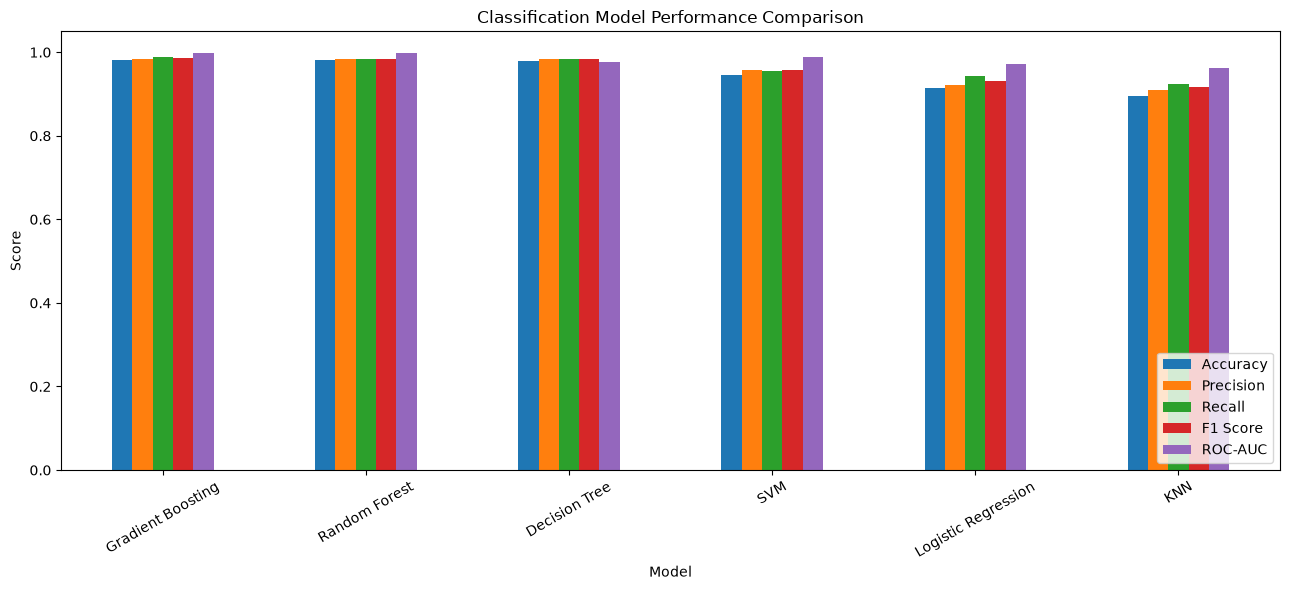

In [44]:
# Visualize model performance

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Classification Model Performance Comparison")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=30)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

### Step 13: Select the Best Model

In [45]:
# Select the model with the highest F1 Score

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best F1 Score:",
    round(results_df.iloc[0]["F1 Score"], 4)
)

Best Model: Gradient Boosting
Best F1 Score: 0.9859


### Step 14: Model Evaluation

#### CLASSIFICATION REPORT

In [46]:
# Import classification report

from sklearn.metrics import classification_report

# Generate predictions

y_pred = best_model.predict(X_test)

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Rejected", "Approved"]
    )
)

Classification Report:

              precision    recall  f1-score   support

    Rejected       0.98      0.97      0.98       323
    Approved       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



### CONFUSION MATRIX

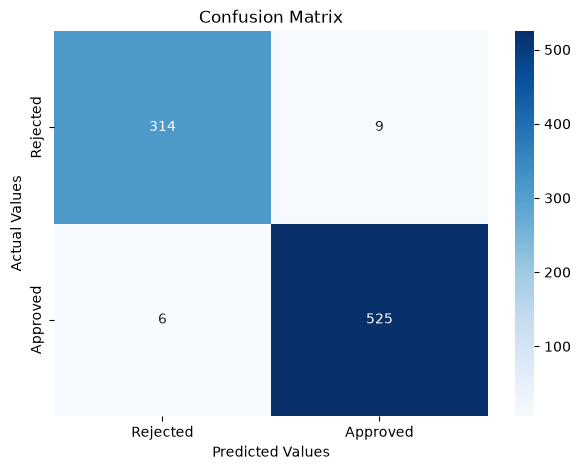

In [47]:
# Import confusion matrix

from sklearn.metrics import confusion_matrix

# Calculate confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

### ROC CURVE

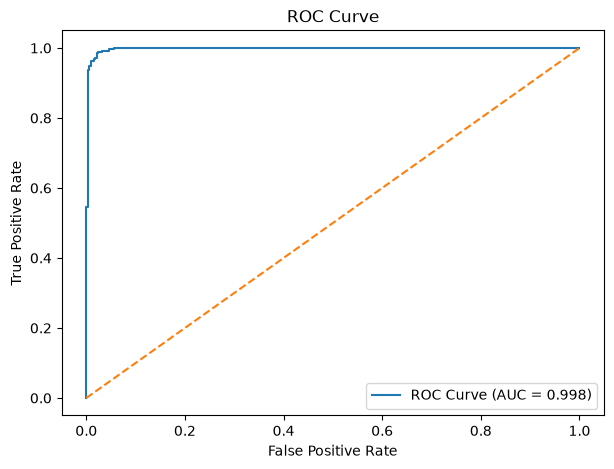

In [48]:
# Import ROC curve utilities

from sklearn.metrics import roc_curve, auc

# Calculate predicted probabilities

y_probability = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

roc_auc = auc(fpr, tpr)

# Plot ROC curve

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

### Step 15: Save the Best Model

In [49]:
# Import joblib for model saving

import joblib

# Save complete trained pipeline

joblib.dump(
    best_model,
    "loan_approval_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


### Step 16: Test the Model with New Input

In [50]:
# Create a sample input using the first test record

sample_input = X_test.iloc[[0]].copy()

print("Sample Applicant Details:")

display(sample_input)

# Predict loan status

prediction = best_model.predict(sample_input)[0]

probability = best_model.predict_proba(sample_input)[0]

if prediction == 1:

    print("Predicted Loan Status: APPROVED")

else:

    print("Predicted Loan Status: REJECTED")

print(
    "Estimated Approval Probability:",
    round(probability[1] * 100, 2),
    "%"
)

Sample Applicant Details:


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
2856,3,Not Graduate,Yes,8300000,31400000,6,674,1000000,1600000,17200000,6100000


Predicted Loan Status: APPROVED
Estimated Approval Probability: 99.8 %


### Step 17: Gradio Deployment

In [51]:
import tqdm as notebook_tqdm

In [52]:
import gradio as gr

C:\Users\Sravan\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [53]:
# Create prediction function for Gradio

def predict_loan_status(*values):

    input_data = pd.DataFrame(
        [values],
        columns=X.columns
    )

    # Predict loan status

    prediction = best_model.predict(input_data)[0]

    probabilities = best_model.predict_proba(input_data)[0]

    if prediction == 1:

        status = "Approved"

    else:

        status = "Rejected"

    return {

        "Predicted Loan Status": status,

        "Approval Probability": f"{probabilities[1] * 100:.2f}%",

        "Rejection Probability": f"{probabilities[0] * 100:.2f}%"

    }

In [54]:
# Create input fields dynamically from dataset columns

input_components = []

for column in X.columns:

    if column in numeric_features:

        component = gr.Number(
            label=column,
            value=float(X[column].median())
        )

    else:

        choices = sorted(
            X[column].dropna().astype(str).unique().tolist()
        )

        component = gr.Dropdown(
            choices=choices,
            value=choices[0],
            label=column
        )

    input_components.append(component)

print("Gradio input fields created successfully!")

Gradio input fields created successfully!


In [55]:
# Create Gradio application

loan_app = gr.Interface(

    fn=predict_loan_status,

    inputs=input_components,

    outputs=gr.JSON(),

    title="Loan Approval Prediction System",

    description="""
    Loan Approval Prediction using Machine Learning.

    Enter applicant details to predict whether
    the loan application is Approved or Rejected.

    This is an educational demonstration,
    not a real lending decision system.
    """

)

# Launch application

loan_app.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


### Step 18: Project Conclusion

# Project Conclusion

In this project, we developed a Loan Approval Prediction system
using supervised Machine Learning classification algorithms.

The project included:

1. Business understanding and problem definition.
2. Dataset loading and inspection.
3. Data cleaning and preprocessing.
4. Exploratory Data Analysis.
5. Feature selection.
6. Train-test splitting.
7. Building multiple classification models.
8. Model comparison and evaluation.
9. Saving the best-performing model.
10. Deploying the model using Gradio.

Multiple classification algorithms were compared using
Accuracy, Precision, Recall, F1-Score and ROC-AUC.

The best-performing model was selected based on its
F1-Score and deployed through an interactive Gradio application.

This project demonstrates how Machine Learning can be
used to analyze historical loan application data and
predict loan approval outcomes.

Note: Predictions are educational estimates and should
not be used as standalone real-world lending decisions.

### Step 19: Final Results

In [56]:
# Display final project results

print("LOAN APPROVAL PREDICTION - FINAL RESULTS")

print("-----------------------------------------")

print("Dataset Records:", df.shape[0])

print("Dataset Features:", X.shape[1])

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

print("Number of Models Compared:", len(models))

print("Best Model:", best_model_name)

print(
    "Accuracy:",
    round(results_df.iloc[0]["Accuracy"] * 100, 2),
    "%"
)

print(
    "Precision:",
    round(results_df.iloc[0]["Precision"], 4)
)

print(
    "Recall:",
    round(results_df.iloc[0]["Recall"], 4)
)

print(
    "F1 Score:",
    round(results_df.iloc[0]["F1 Score"], 4)
)

print(
    "ROC-AUC:",
    round(results_df.iloc[0]["ROC-AUC"], 4)
)

LOAN APPROVAL PREDICTION - FINAL RESULTS
-----------------------------------------
Dataset Records: 4269
Dataset Features: 11
Training Records: 3415
Testing Records: 854
Number of Models Compared: 6
Best Model: Gradient Boosting
Accuracy: 98.24 %
Precision: 0.9831
Recall: 0.9887
F1 Score: 0.9859
ROC-AUC: 0.9976
